In [1]:
"Up and running"

'Up and running'

In [7]:
# Third-party modules
import seaborn as sns
import matplotlib.pyplot as plt

# Custom modules
from misc import paths
from misc import config
from misc.logger import logger
from entity.collection import ProteinPairCollection
logger.info('Importing modules completed')

2521056134.py INFO Importing modules completed


In [2]:
# Load protein pairs
protein_path = paths.COLLECTIONS / 'families.prot'
file_path = paths.COLLECTIONS / 'families.pair'
collection = ProteinPairCollection(
    file_path=file_path,
    proteins=protein_path,
)

In [4]:
# Compute lengths
lengths = [len(pair.p1.seq) + len(pair.p2.seq) for pair in collection]

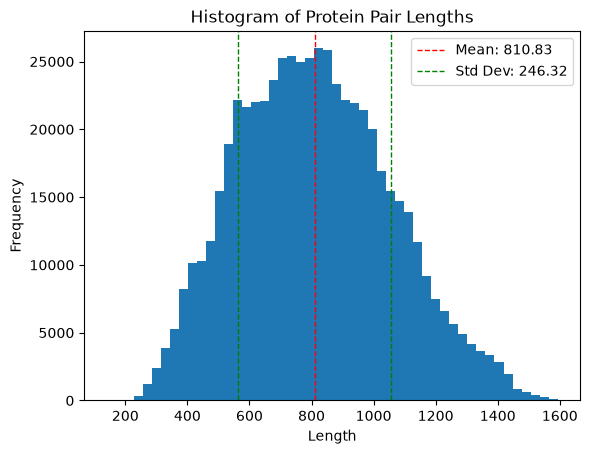

In [5]:
# Plot histogram of lengths
plt.hist(lengths, bins=50)
mean = sum(lengths) / len(lengths)
variance = sum((x - mean) ** 2 for x in lengths) / len(lengths)
std_dev = variance ** 0.5
plt.axvline(mean, color='r', linestyle='dashed', linewidth=1, label=f'Mean: {mean:.2f}')
plt.axvline(mean + std_dev, color='g', linestyle='dashed', linewidth=1, label=f'Std Dev: {std_dev:.2f}')
plt.axvline(mean - std_dev, color='g', linestyle='dashed', linewidth=1)
plt.legend()
plt.title('Histogram of Protein Pair Lengths')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()

In [3]:
# Compute lengths per family
pairs_per_family = {
    family : []
    for family in config.FAMILIES
}
for pair in collection:
    if pair.p1.family in config.FAMILIES:
        pairs_per_family[pair.p1.family].append(pair)
    if pair.p2.family in config.FAMILIES:
        pairs_per_family[pair.p2.family].append(pair)

lengths_per_family = {
    family : [len(pair.p1.seq) + len(pair.p2.seq) for pair in pairs]
    for family, pairs in pairs_per_family.items()
}

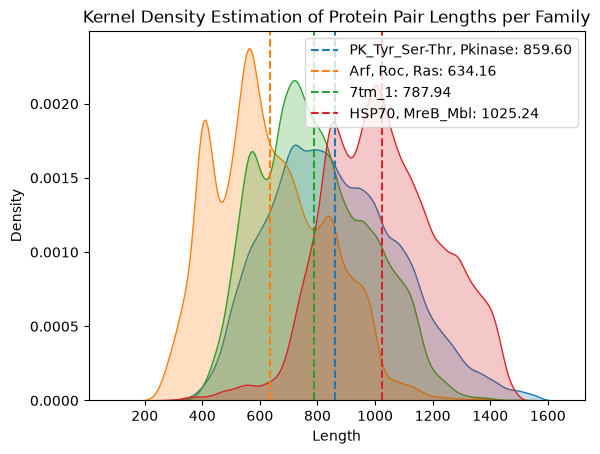

In [15]:
# Plot histograms of lengths per family
for family, lengths in lengths_per_family.items():
    sns.kdeplot(lengths, fill=True)
    plt.axvline(
        sum(lengths) / len(lengths), 
        color=sns.color_palette()[config.FAMILIES.index(family)],
        linestyle='dashed', 
        label=f'{family}: {sum(lengths) / len(lengths):.2f}'
    )
plt.title('Kernel Density Estimation of Protein Pair Lengths per Family')
plt.xlabel('Length')
plt.ylabel('Density')
plt.legend()
plt.show()